In [5]:
""" Student Pass/Fail Prediction
Predicting student outcomes (Pass/Fail) based on two features:
1. **Study Hours**
2. **Attendance (%)**
"""

import pandas as pd
import matplotlib.pyplot as plt

In [6]:
# 1. Simple manual dataset with 8 students
data = {
    'Study_Hours': [2.0, 8.5, 1.5, 9.0, 5.0, 10.0, 3.5, 7.5,4.0,5.0,3.5,2.5,3.7,5.6,6.5],
    'Attendance':  [60,  90,  55,  85,  70,  95,  65,  80,90,34,23,45,56,67,75],
    'Passed':      [0,   1,   0,   1,   0,   1,   0,   1,0,1,1,1,0,0,1]  # 0 = Fail, 1 = Pass
}

df = pd.DataFrame(data)

In [7]:
#2. Simple classification rule: Pass if (Study_Hours * 10) + Attendance > 140
def predict_pass(study_hours, attendance):
    score = (study_hours * 10) + attendance
    return 1 if score > 140 else 0

df['Predicted'] = df.apply(lambda row: predict_pass(row['Study_Hours'], row['Attendance']), axis=1)

print("--- Student Dataset ---")
display(df)

--- Student Dataset ---


,Study_Hours,Attendance,Passed,Predicted
0,2.0,60,0,0
1,8.5,90,1,1
2,1.5,55,0,0
3,9.0,85,1,1
4,5.0,70,0,0
5,10.0,95,1,1
6,3.5,65,0,0
7,7.5,80,1,1
8,4.0,90,0,0
9,5.0,34,1,0


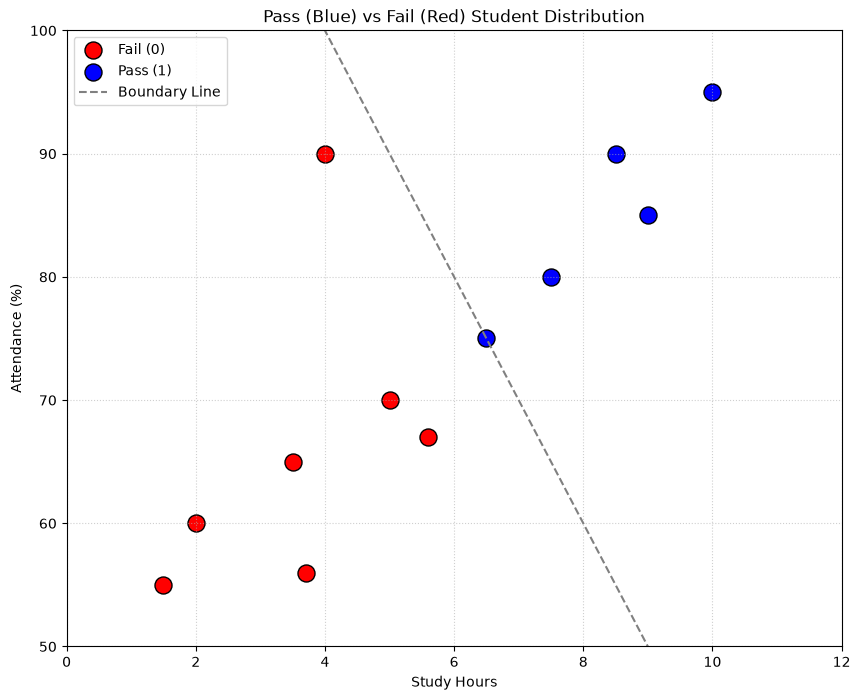

In [8]:

# 3. Plotting with Red for Fail and Blue for Pass
plt.figure(figsize=(10, 8))

# Separate passed and failed students for clear plotting
failed = df[df['Passed'] == 0]
passed = df[df['Passed'] == 1]

# Plot Failed as Red circles and Passed as Blue circles
plt.scatter(failed['Study_Hours'], failed['Attendance'], color='red', label='Fail (0)', s=150, edgecolors='black')
plt.scatter(passed['Study_Hours'], passed['Attendance'], color='blue', label='Pass (1)', s=150, edgecolors='black')

# Plot the linear decision boundary line
x_line = [0, 12]
y_line = [140, 20]
plt.plot(x_line, y_line, color='gray', linestyle='--', label='Boundary Line')

plt.title('Pass (Blue) vs Fail (Red) Student Distribution')
plt.xlabel('Study Hours')
plt.ylabel('Attendance (%)')
plt.xlim(0, 12)
plt.ylim(50, 100)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [9]:

## House Price Category Predictor
## Predict whether a house is Budget, Mid-range, or Luxury based on its size (sqft) and number of bedrooms using a Decision Tree Classifier.

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Step 1: build_dataset()
def build_dataset():
    # Dataset defined in the setup screenshot
    house_size = [500, 650, 750, 850, 1200, 1400, 1600, 1800, 2500, 2800, 3200, 3600, 1000, 1200, 1400, 1500, 1600, 1700, 1800, 1900]
    bedrooms = [1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 5, 9, 2, 3,4,5,4,5,6,2]
    category = ["Budget"] * 5 + ["Mid-range"] * 8 + ["Luxury"] * 7
    
    # Feature matrix X and target y
    X = pd.DataFrame({
        'Size': house_size,
        'Bedrooms': bedrooms
    })
    y = pd.Series(category)
    return X, y

In [10]:

# Step 2: split_data()
def split_data(X, y):
    return train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Step 3: train_model()
def train_model(X_train, y_train):
    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)
    return model

# Step 4: predict_price_category()
def predict_price_category(model, size, bedrooms):
    prediction = model.predict([[size, bedrooms]])
    return prediction[0]

# Step 5: evaluate_model()
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    return accuracy_score(y_test, y_pred)


In [11]:
# --- Execution & Verification ---#
X, y = build_dataset()
X_train, X_test, y_train, y_test = split_data(X, y)
model = train_model(X_train, y_train)

# Prediction for a new 1700 sqft, 3 bedroom house
prediction_1700 = predict_price_category(model, 1700, 3)
# Accuracy on the split test set
accuracy = evaluate_model(model, X_test, y_test)

print(f"Dataset Size: {len(X)} houses")
print(f"Prediction for 1700 sqft & 3 bedrooms: '{prediction_1700}'")
print(f"Model Accuracy on Test Set: {accuracy * 100:.1f}%")

Dataset Size: 20 houses
Prediction for 1700 sqft & 3 bedrooms: 'Mid-range'
Model Accuracy on Test Set: 80.0%


c:\Users\USER\Desktop\python\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
